# Задача 7. Нейронные сети

* **Дедлайн**: 28.03.2025, 23:59
* **Основной полный балл**: 5
* **Максимум баллов**: 10

## Задача

- [x] Найти данные в виде изображений для задачи классификации (**MNIST**).
- [x] Реализовать классы, необходимые для построения сети со следующими слоями:
  - `FullyConnectedLayer`
  - `ReluLayer`
  - `FullyConnectedLayer`
- [x] Использовать `CrossEntropyLoss` и **L2-регуляризацию**.
- [x] Обучить модель на тренировочных данных, подобрать параметры (особенно learning rate) на валидационной
  выборке и оценить качество на тестовой. Анализировать графики train/val loss, проверять на каждом шаге корректность
  вычисления градиентов с помощью разностной оценки.
- [x] * (**+2 балла**) Добавить **Batch Normalization**.
- [x] * (**+2 балла**) В качестве оптимизатора использовать **Momentum** и **RMSprop**.
- [x] * (**+1 балл**) Также реализовать оптимизатор **Adam**.

## Импорты и константы

Вся сеть — слои, функция потерь, оптимизаторы — реализована с нуля на `numpy` с ручным обратным распространением
ошибки (backprop), без фреймворков и автоградации.

In [1]:
import gzip
import os
import struct
import urllib.request
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

## Датасет: MNIST

**MNIST** — классический датасет изображений рукописных цифр от 0 до 9.

- 60 000 изображений для обучения и 10 000 для теста;
- каждое изображение 28 × 28 пикселей в градациях серого (значения 0–255);
- метка — цифра от 0 до 9.

Данные лежат в `../data/mnist/` (формат IDX, уже скачаны). Если файлов нет — ячейка ниже скачает их с официального
зеркала.

In [2]:
def load_idx_image(path):
    with gzip.open(path, "rb") as f:
        magic = struct.unpack(">I", f.read(4))[0]
        assert magic == 2051, f"bad magic {magic}"
        n = struct.unpack(">I", f.read(4))[0]
        rows = struct.unpack(">I", f.read(4))[0]
        cols = struct.unpack(">I", f.read(4))[0]
        data = np.frombuffer(f.read(), dtype=np.uint8)
        return data.reshape(n, rows, cols)


def load_idx_label(path):
    with gzip.open(path, "rb") as f:
        magic = struct.unpack(">I", f.read(4))[0]
        assert magic == 2049, f"bad magic {magic}"
        n = struct.unpack(">I", f.read(4))[0]
        return np.frombuffer(f.read(), dtype=np.uint8)


DATA_DIR = "../data/mnist"
URLS = {
    "train-images-idx3-ubyte.gz": "https://ossci-datasets.s3.amazonaws.com/mnist/train-images-idx3-ubyte.gz",
    "train-labels-idx1-ubyte.gz": "https://ossci-datasets.s3.amazonaws.com/mnist/train-labels-idx1-ubyte.gz",
    "t10k-images-idx3-ubyte.gz": "https://ossci-datasets.s3.amazonaws.com/mnist/t10k-images-idx3-ubyte.gz",
    "t10k-labels-idx1-ubyte.gz": "https://ossci-datasets.s3.amazonaws.com/mnist/t10k-labels-idx1-ubyte.gz",
}

if not os.path.exists(os.path.join(DATA_DIR, "train-images-idx3-ubyte.gz")):
    os.makedirs(DATA_DIR, exist_ok=True)
    for name, url in URLS.items():
        print("Скачиваю", name)
        urllib.request.urlretrieve(url, os.path.join(DATA_DIR, name))

X_train = load_idx_image(os.path.join(DATA_DIR, "train-images-idx3-ubyte.gz"))
y_train = load_idx_label(os.path.join(DATA_DIR, "train-labels-idx1-ubyte.gz"))
X_test = load_idx_image(os.path.join(DATA_DIR, "t10k-images-idx3-ubyte.gz"))
y_test = load_idx_label(os.path.join(DATA_DIR, "t10k-labels-idx1-ubyte.gz"))

print(f"X_train: {X_train.shape}, метки: {np.unique(y_train)}")
print(f"X_test:  {X_test.shape},  метки: {np.unique(y_test)}")
print(f"Диапазон пикселей: [{X_train.min()}, {X_train.max()}]")

X_train: (60000, 28, 28), метки: [0 1 2 3 4 5 6 7 8 9]
X_test:  (10000, 28, 28),  метки: [0 1 2 3 4 5 6 7 8 9]
Диапазон пикселей: [0, 255]


Посмотрим на примеры изображений и распределение классов.

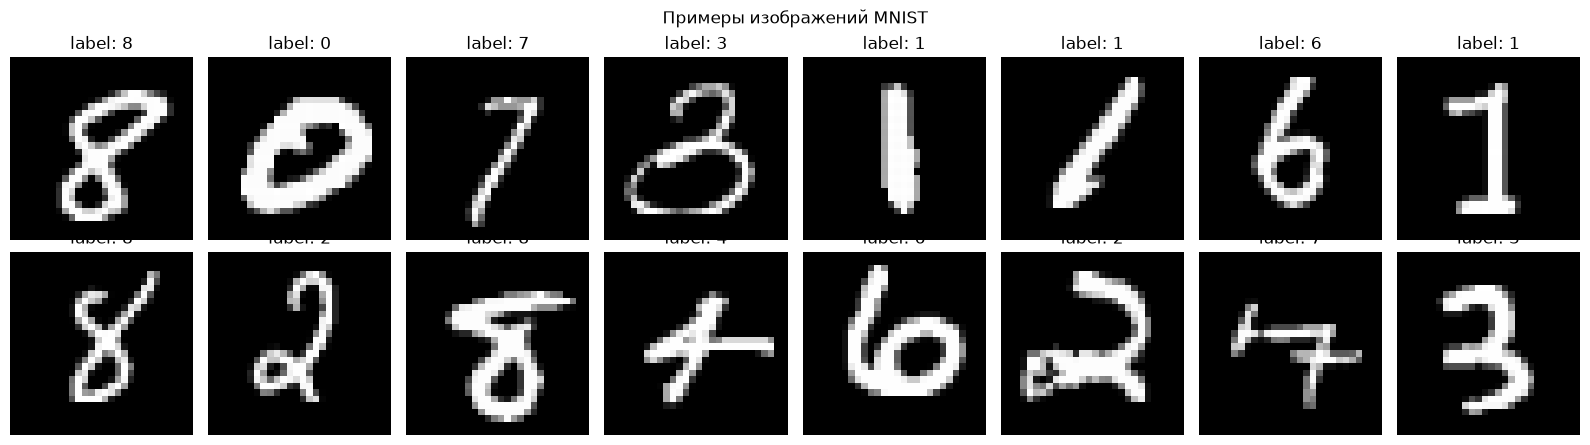

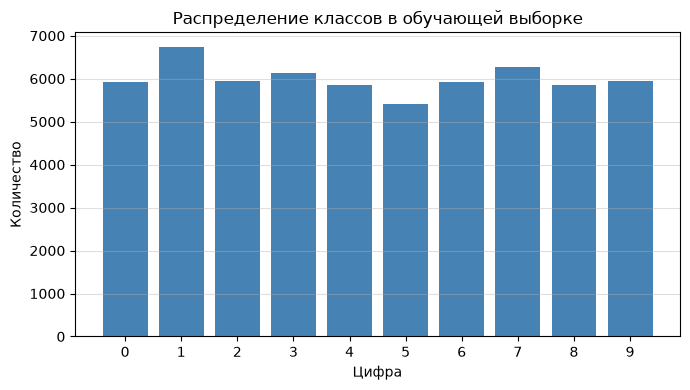

In [3]:
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
rng = np.random.default_rng(42)
idx = rng.choice(len(X_train), 16, replace=False)
for ax, i in zip(axes.ravel(), idx):
    ax.imshow(X_train[i], cmap="gray")
    ax.set_title(f"label: {y_train[i]}")
    ax.axis("off")
plt.suptitle("Примеры изображений MNIST")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
classes, counts = np.unique(y_train, return_counts=True)
plt.bar(classes, counts, color="steelblue")
plt.xticks(classes)
plt.xlabel("Цифра"); plt.ylabel("Количество")
plt.title("Распределение классов в обучающей выборке")
plt.grid(axis="y", alpha=0.4)
plt.tight_layout()
plt.show()

## Препроцессинг

Разделим обучающую выборку на train/val (90/10), нормализуем пиксели стандартными статистиками MNIST
(mean = 0.1307, std = 0.3081) и развернём изображения 28 × 28 в векторы длины 784.

In [4]:
rng_split = np.random.default_rng(1337)
perm = rng_split.permutation(len(X_train))
n_val = int(0.1 * len(X_train))

X_train, X_val = X_train[perm[n_val:]], X_train[perm[:n_val]]
y_train, y_val = y_train[perm[n_val:]], y_train[perm[:n_val]]

MEAN, STD = 0.1307, 0.3081
X_train = ((X_train / 255.0) - MEAN) / STD
X_val = ((X_val / 255.0) - MEAN) / STD
X_test = ((X_test / 255.0) - MEAN) / STD

X_train = X_train.reshape(len(X_train), -1)
X_val = X_val.reshape(len(X_val), -1)
X_test = X_test.reshape(len(X_test), -1)

print(f"train: {X_train.shape}, val: {X_val.shape}, test: {X_test.shape}")
print(f"После нормализации: mean = {X_train.mean():.4f}, std = {X_train.std():.4f}")

train: (54000, 784), val: (6000, 784), test: (10000, 784)
После нормализации: mean = -0.0001, std = 1.0001


## Реализация слоёв

### FullyConnectedLayer

Полносвязный слой: $y = x W + b$. `backward` возвращает градиент по входу и накапливает градиенты по параметрам.

### ReluLayer

Активация ReLU: $y = \max(0, x)$. В `backward` градиент пропускается только через положительные входы.

In [5]:
class FullyConnectedLayer:
    """Полносвязный слой: y = x @ W + b."""

    def __init__(self, in_features, out_features, seed=0):
        rng = np.random.default_rng(seed)
        self.W = rng.normal(0, np.sqrt(2.0 / in_features), (in_features, out_features))  # He-инициализация
        self.b = np.zeros(out_features)
        self.dW = np.zeros_like(self.W)
        self.db = np.zeros_like(self.b)

    def forward(self, x, training=True):
        self.x = x
        return x @ self.W + self.b

    def backward(self, dout):
        self.dW += self.x.T @ dout
        self.db += dout.sum(axis=0)
        return dout @ self.W.T

    def params(self):
        return [self.W, self.b]

    def grads(self):
        return [self.dW, self.db]


class ReluLayer:
    """ReLU-активация: y = max(0, x)."""

    def forward(self, x, training=True):
        self.mask = x > 0
        return x * self.mask

    def backward(self, dout):
        return dout * self.mask

    def params(self):
        return []

    def grads(self):
        return []

### CrossEntropyLoss + L2-регуляризация

`CrossEntropyLoss` — средний по батчу минус логарифм вероятности правильного класса (softmax + NLL).
**L2-регуляризация** добавляет к функции потерь штраф $\lambda \sum \|W\|^2$ за норму весов (и, соответственно,
$2\lambda W$ к их градиентам); веса смещений и параметры BatchNorm не штрафуем.

In [6]:
class CrossEntropyLoss:
    """Softmax + кросс-энтропия (средняя по батчу)."""

    def __init__(self, n_classes):
        self.n_classes = n_classes

    def forward(self, logits, y):
        N = logits.shape[0]
        logits = logits - logits.max(axis=1, keepdims=True)  # численная устойчивость
        exp = np.exp(logits)
        probs = exp / exp.sum(axis=1, keepdims=True)
        loss = -np.log(probs[np.arange(N), y] + 1e-12).mean()
        one_hot = np.eye(self.n_classes)[y]
        self.dlogits = (probs - one_hot) / N  # dL/dlogits
        return loss

    def backward(self):
        return self.dlogits


def l2_reg(model, l2_lambda):
    """L2-штраф по весам полносвязных слоёв (bias и BatchNorm не штрафуем)."""
    return l2_lambda * sum((layer.W ** 2).sum() for layer in model.layers
                           if isinstance(layer, FullyConnectedLayer))


def add_l2_grads(model, l2_lambda):
    """Добавляем 2*lambda*W к градиентам весов."""
    for layer in model.layers:
        if isinstance(layer, FullyConnectedLayer):
            layer.dW += 2 * l2_lambda * layer.W

### Batch Normalization (+2 балла)

`BatchNormLayer` нормализует активации внутри батча: $\hat x = (x - \mu_B)/\sqrt{\sigma_B^2 + \epsilon}$, затем
масштабирует и сдвигает на обучаемые параметры $\gamma, \beta$. В режиме обучения используются статистики батча
(градиенты через них учитываются в `backward`), в режиме инференса — скользящие средние, накопленные при обучении.

In [7]:
class BatchNormLayer:
    """Batch Normalization: обучение по статистикам батча, инференс по скользящим средним."""

    def __init__(self, dim, eps=1e-5, momentum=0.9, seed=0):
        rng = np.random.default_rng(seed)
        self.eps = eps
        self.momentum = momentum
        self.gamma = rng.normal(1.0, 0.02, dim)
        self.beta = np.zeros(dim)
        self.dgamma = np.zeros(dim)
        self.dbeta = np.zeros(dim)
        self.running_mean = np.zeros(dim)
        self.running_var = np.ones(dim)

    def forward(self, x, training=True):
        if training:
            mu = x.mean(axis=0)
            var = x.var(axis=0)
            self.x_hat = (x - mu) / np.sqrt(var + self.eps)
            self.mu, self.var = mu, var
            self.running_mean = self.momentum * self.running_mean + (1 - self.momentum) * mu
            self.running_var = self.momentum * self.running_var + (1 - self.momentum) * var
            return self.gamma * self.x_hat + self.beta
        x_hat = (x - self.running_mean) / np.sqrt(self.running_var + self.eps)
        return self.gamma * x_hat + self.beta

    def backward(self, dout):
        N = dout.shape[0]
        self.dgamma += (dout * self.x_hat).sum(axis=0)
        self.dbeta += dout.sum(axis=0)
        dx_hat = dout * self.gamma
        inv_std = 1.0 / np.sqrt(self.var + self.eps)
        # стандартный backprop через нормализацию
        dx = (1.0 / N) * inv_std * (
            N * dx_hat
            - dx_hat.sum(axis=0)
            - self.x_hat * (dx_hat * self.x_hat).sum(axis=0)
        )
        return dx

    def params(self):
        return [self.gamma, self.beta]

    def grads(self):
        return [self.dgamma, self.dbeta]

Сеть из требуемых слоёв: **FullyConnected → [BatchNorm] → ReLU → FullyConnected**.

In [8]:
class MLP:
    """Сеть: FullyConnected -> [BatchNorm] -> ReLU -> FullyConnected."""

    def __init__(self, in_dim=784, hidden=256, n_classes=10, use_bn=False):
        self.layers = []
        self.layers.append(FullyConnectedLayer(in_dim, hidden, seed=1))
        if use_bn:
            self.layers.append(BatchNormLayer(hidden, seed=2))
        self.layers.append(ReluLayer())
        self.layers.append(FullyConnectedLayer(hidden, n_classes, seed=3))

    def forward(self, x, training=True):
        for layer in self.layers:
            x = layer.forward(x, training)
        return x

    def backward(self, dout):
        for layer in reversed(self.layers):
            dout = layer.backward(dout)

    def all_params(self):
        """(значение, градиент) для всех обучаемых параметров."""
        params = []
        for layer in self.layers:
            params.extend(zip(layer.params(), layer.grads()))
        return params

    def param_names(self):
        names = []
        for i, layer in enumerate(self.layers):
            if isinstance(layer, FullyConnectedLayer):
                names += [f"fc{i//2+1}_W", f"fc{i//2+1}_b"]
            elif isinstance(layer, BatchNormLayer):
                names += ["bn_gamma", "bn_beta"]
        return names

## Оптимизаторы

Реализуем три оптимизатора (+2 балла за **Momentum** и **RMSprop**, +1 балл за **Adam**). Все работают через общий
интерфейс: `step()` обновляет параметры по накопленным градиентам.

- **Momentum** — к обновлению добавляется инерция: $v = \mu v + g$, $W \leftarrow W - \eta v$;
- **RMSprop** — нормировка градиента на корень из экспоненциального среднего квадратов:
  $s = \rho s + (1-\rho) g^2$, $W \leftarrow W - \eta \, g / \sqrt{s + \epsilon}$;
- **Adam** — Momentum + RMSprop с коррекцией смещения на первых шагах.

In [9]:
class Momentum:
    """SGD с моментом (инерцией)."""

    def __init__(self, params, lr=1e-3, momentum=0.9):
        self.params = params
        self.lr = lr
        self.momentum = momentum
        self.v = [np.zeros_like(p) for p, g in params]

    def step(self):
        for (p, g), v in zip(self.params, self.v):
            v[:] = self.momentum * v + g
            p -= self.lr * v


class RMSprop:
    """RMSprop: нормировка градиента на экспоненциальное среднее квадратов."""

    def __init__(self, params, lr=1e-3, rho=0.99, eps=1e-8):
        self.params = params
        self.lr = lr
        self.rho = rho
        self.eps = eps
        self.s = [np.zeros_like(p) for p, g in params]

    def step(self):
        for (p, g), s in zip(self.params, self.s):
            s[:] = self.rho * s + (1 - self.rho) * g * g
            p -= self.lr * g / (np.sqrt(s) + self.eps)


class Adam:
    """Adam: моменты 1-го и 2-го порядка с коррекцией смещения."""

    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8):
        self.params = params
        self.lr = lr
        self.beta1, self.beta2 = betas
        self.eps = eps
        self.m = [np.zeros_like(p) for p, g in params]
        self.v = [np.zeros_like(p) for p, g in params]
        self.t = 0

    def step(self):
        self.t += 1
        for (p, g), m, v in zip(self.params, self.m, self.v):
            m[:] = self.beta1 * m + (1 - self.beta1) * g
            v[:] = self.beta2 * v + (1 - self.beta2) * g * g
            m_hat = m / (1 - self.beta1 ** self.t)
            v_hat = v / (1 - self.beta2 ** self.t)
            p -= self.lr * m_hat / (np.sqrt(v_hat) + self.eps)


def make_optimizer(name, model, lr):
    params = model.all_params()
    if name == "Momentum":
        return Momentum(params, lr=lr)
    if name == "RMSprop":
        return RMSprop(params, lr=lr)
    if name == "Adam":
        return Adam(params, lr=lr)
    raise ValueError(name)

## Проверка градиентов разностной оценкой

Функция `gradient_check` сравнивает аналитические градиенты (нашего backprop) с численными: для случайных координат
каждого параметра считаем $\dfrac{L(\theta + \epsilon) - L(\theta - \epsilon)}{2\epsilon}$ и сравниваем
с аналитическим значением. Относительная ошибка порядка $10^{-7}$ означает, что обратное распространение реализовано
верно.

Проверяем обе архитектуры: без BatchNorm и с BatchNorm (в режиме обучения).

Одно ожидаемое наблюдение: градиент по смещению полносвязного слоя, стоящего **перед** BatchNorm, практически нулевой — нормализация вычитает среднее по батчу и «гасит» постоянный сдвиг входов. Поэтому для почти нулевых градиентов сравниваем абсолютную разницу, а не относительную: это не ошибка реализации.

In [10]:
def gradient_check(model, loss_fn, X, y, eps=1e-5, num_checks=3, l2_lambda=0.0):
    """Сравнивает аналитические градиенты с численными; возвращает [(имя, max_rel_err)]."""
    for layer in model.layers:
        for grad in layer.grads():
            grad[:] = 0.0

    logits = model.forward(X, training=True)
    loss_fn.forward(logits, y)
    model.backward(loss_fn.backward())
    add_l2_grads(model, l2_lambda)

    results = []
    for name, (P, G) in zip(model.param_names(), model.all_params()):
        rng = np.random.default_rng(0)
        idx = rng.choice(P.size, size=min(num_checks, P.size), replace=False)
        flat = P.ravel()
        analytic = G.ravel()[idx]
        numeric = np.zeros_like(analytic)
        for k, i in enumerate(idx):
            old = flat[i]
            flat[i] = old + eps
            loss_plus = loss_fn.forward(model.forward(X, training=True), y) + l2_reg(model, l2_lambda)
            flat[i] = old - eps
            loss_minus = loss_fn.forward(model.forward(X, training=True), y) + l2_reg(model, l2_lambda)
            flat[i] = old
            numeric[k] = (loss_plus - loss_minus) / (2 * eps)
        scale = np.maximum(np.abs(analytic), np.abs(numeric))
        # если оба градиента ~0 (например, bias перед BatchNorm — нормализация гасит сдвиг),
        # относительная ошибка бессмысленна: сравниваем абсолютную разницу
        err = np.where(scale < 1e-7, np.abs(analytic - numeric),
                       np.abs(analytic - numeric) / (scale + 1e-12))
        results.append((name, err.max()))
    return results


X_check = X_train[:64]
y_check = y_train[:64]

for use_bn in [False, True]:
    model = MLP(in_dim=784, hidden=32, n_classes=10, use_bn=use_bn)
    loss_fn = CrossEntropyLoss(10)
    print(f"=== архитектура: FC -> {'BN -> ' if use_bn else ''}ReLU -> FC (с L2 = 1e-3) ===")
    max_err = 0.0
    for name, err in gradient_check(model, loss_fn, X_check, y_check, l2_lambda=1e-3):
        print(f"  {name:10s}: max rel err = {err:.2e}")
        max_err = max(max_err, err)
    print(f"  СУММАРНО max rel err = {max_err:.2e}\n")

=== архитектура: FC -> ReLU -> FC (с L2 = 1e-3) ===
  fc1_W     : max rel err = 1.48e-09
  fc1_b     : max rel err = 1.30e-09
  fc2_W     : max rel err = 1.14e-09
  fc2_b     : max rel err = 2.17e-10
  СУММАРНО max rel err = 1.48e-09

=== архитектура: FC -> BN -> ReLU -> FC (с L2 = 1e-3) ===
  fc1_W     : max rel err = 6.85e-08
  fc1_b     : max rel err = 2.22e-11
  bn_gamma  : max rel err = 8.61e-10
  bn_beta   : max rel err = 1.93e-09
  fc2_W     : max rel err = 4.85e-10
  fc2_b     : max rel err = 4.30e-10
  СУММАРНО max rel err = 6.85e-08



## Обучение

Функция `train_model` обучает модель мини-батчным градиентным спуском с L2-регуляризацией. После **каждой эпохи**
градиенты проверяются разностной оценкой на случайном батче (печатается максимальная относительная ошибка) — так на
каждом шаге мы убеждаемся в корректности backprop. На валидационной выборке модель работает в режиме инференса
(для BatchNorm — со скользящими средними).

In [11]:
def evaluate(model, loss_fn, X, y, batch_size=1024):
    """Loss и точность в режиме инференса."""
    losses, correct, total = [], 0, 0
    for i in range(0, len(X), batch_size):
        xb, yb = X[i:i + batch_size], y[i:i + batch_size]
        logits = model.forward(xb, training=False)
        losses.append(loss_fn.forward(logits, yb))
        correct += (logits.argmax(axis=1) == yb).sum()
        total += len(yb)
    return float(np.mean(losses)), correct / total


def train_model(model, optimizer, loss_fn, X_tr, y_tr, X_val, y_val,
                epochs=10, batch_size=256, l2_lambda=0.0, seed=0, grad_check_every=1,
                X_gc=None, y_gc=None, verbose=True):
    history = {"train_loss": [], "val_loss": [], "val_acc": [], "train_acc": [], "grad_err": []}
    rng = np.random.default_rng(seed)
    n = len(X_tr)
    for epoch in range(epochs):
        perm = rng.permutation(n)
        epoch_loss, n_batches, correct, total = 0.0, 0, 0, 0
        for start in range(0, n, batch_size):
            idx = perm[start:start + batch_size]
            xb, yb = X_tr[idx], y_tr[idx]
            for layer in model.layers:      # обнуляем градиенты
                for grad in layer.grads():
                    grad[:] = 0.0

            logits = model.forward(xb, training=True)
            loss = loss_fn.forward(logits, yb) + l2_reg(model, l2_lambda)
            model.backward(loss_fn.backward())
            add_l2_grads(model, l2_lambda)
            optimizer.step()

            epoch_loss += loss
            n_batches += 1
            correct += (logits.argmax(axis=1) == yb).sum()
            total += len(yb)

        if (epoch % grad_check_every) == 0:
            gc = gradient_check(model, loss_fn, X_gc, y_gc, l2_lambda=l2_lambda)
            max_err = max(e for _, e in gc)
            history["grad_err"].append(max_err)
            if verbose:
                print(f"epoch {epoch}: grad check max rel err = {max_err:.2e}")

        val_loss, val_acc = evaluate(model, loss_fn, X_val, y_val)
        history["train_loss"].append(epoch_loss / n_batches)
        history["train_acc"].append(correct / total)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        if verbose:
            print(f"epoch {epoch:2d}: train loss {history['train_loss'][-1]:.4f}, "
                  f"val loss {val_loss:.4f}, val acc {val_acc:.4f}")
    return history

Сначала быстрый демонстрационный прогон (Adam, без BatchNorm, 3 эпохи) — убеждаемся, что loss убывает,
а градиенты на каждом шаге проверены.

epoch 0: grad check max rel err = 1.39e-07
epoch  0: train loss 0.3814, val loss 0.1485, val acc 0.9555


epoch 1: grad check max rel err = 2.41e-08
epoch  1: train loss 0.1829, val loss 0.1091, val acc 0.9672


epoch 2: grad check max rel err = 1.50e-06
epoch  2: train loss 0.1395, val loss 0.0972, val acc 0.9682


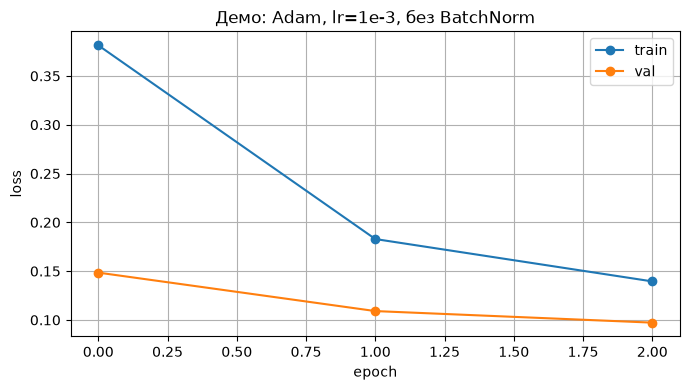

In [12]:
model = MLP(in_dim=784, hidden=256, n_classes=10, use_bn=False)
loss_fn = CrossEntropyLoss(10)
optimizer = Adam(model.all_params(), lr=1e-3)
history = train_model(model, optimizer, loss_fn, X_train, y_train, X_val, y_val,
                      epochs=3, batch_size=256, l2_lambda=1e-4, seed=0,
                      X_gc=X_train[:64], y_gc=y_train[:64])

plt.figure(figsize=(7, 4))
plt.plot(history["train_loss"], marker="o", label="train")
plt.plot(history["val_loss"], marker="o", label="val")
plt.xlabel("epoch"); plt.ylabel("loss")
plt.title("Демо: Adam, lr=1e-3, без BatchNorm")
plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()

## Подбор гиперпараметров на валидационной выборке

Перебираем 18 комбинаций: **3 оптимизатора** (Adam, RMSprop, Momentum) × **2 варианта сети** (с BatchNorm и без) ×
**3 learning rate** (1e-2, 1e-3, 1e-4). Каждая модель обучается 10 эпох; лучшие конфигурации отбираются по точности
на валидации, затем проверяются на тесте.

In [13]:
OPTIMIZERS = ["Adam", "RMSprop", "Momentum"]
LEARNING_RATES = [1e-2, 1e-3, 1e-4]
EPOCHS = 10
L2 = 1e-4
BATCH_SIZE = 256

t0 = perf_counter()
results = {}
for opt_name in OPTIMIZERS:
    for lr in LEARNING_RATES:
        for use_bn in [False, True]:
            tag = f"{opt_name}, lr={lr}, bn={use_bn}"
            model = MLP(in_dim=784, hidden=256, n_classes=10, use_bn=use_bn)
            loss_fn = CrossEntropyLoss(10)
            optimizer = make_optimizer(opt_name, model, lr)
            hist = train_model(model, optimizer, loss_fn, X_train, y_train, X_val, y_val,
                               epochs=EPOCHS, batch_size=BATCH_SIZE, l2_lambda=L2, seed=0,
                               X_gc=X_train[:64], y_gc=y_train[:64], verbose=False)
            results[tag] = {"model": model, "loss_fn": loss_fn, "history": hist}
            print(f"{tag:32s}: val acc = {hist['val_acc'][-1]:.4f}  "
                  f"(последний grad err = {hist['grad_err'][-1]:.2e})", flush=True)
print(f"\nСвип из 18 конфигураций выполнен за {perf_counter() - t0:.0f} с")

Adam, lr=0.01, bn=False         : val acc = 0.9645  (последний grad err = 3.46e-06)


Adam, lr=0.01, bn=True          : val acc = 0.9665  (последний grad err = 2.74e-08)


Adam, lr=0.001, bn=False        : val acc = 0.9797  (последний grad err = 2.79e-08)


Adam, lr=0.001, bn=True         : val acc = 0.9793  (последний grad err = 3.25e-07)


Adam, lr=0.0001, bn=False       : val acc = 0.9638  (последний grad err = 2.01e-08)


...

Momentum, lr=0.001, bn=False    : val acc = 0.9442  (последний grad err = 1.55e-08)


Momentum, lr=0.001, bn=True     : val acc = 0.9397  (последний grad err = 1.17e-07)


Momentum, lr=0.0001, bn=False   : val acc = 0.8807  (последний grad err = 2.50e-07)


Momentum, lr=0.0001, bn=True    : val acc = 0.8605  (последний grad err = 6.07e-07)



Свип из 18 конфигураций выполнен за 538 с


Построим графики train/val loss всех 18 конфигураций (по оптимизатору — фигура 2×3: строки — learning rate,
столбцы — с/без BatchNorm).

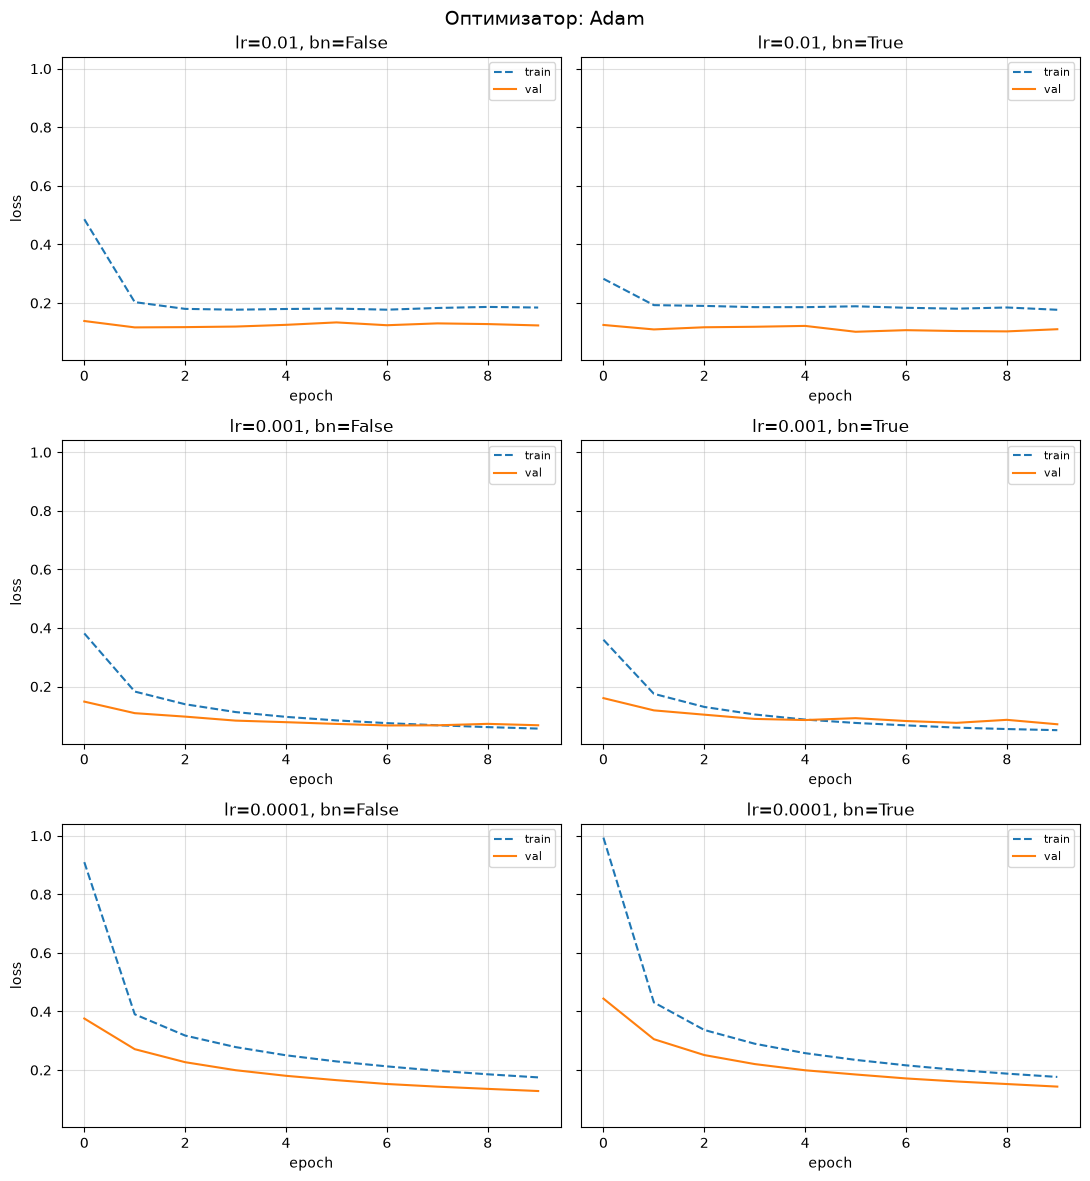

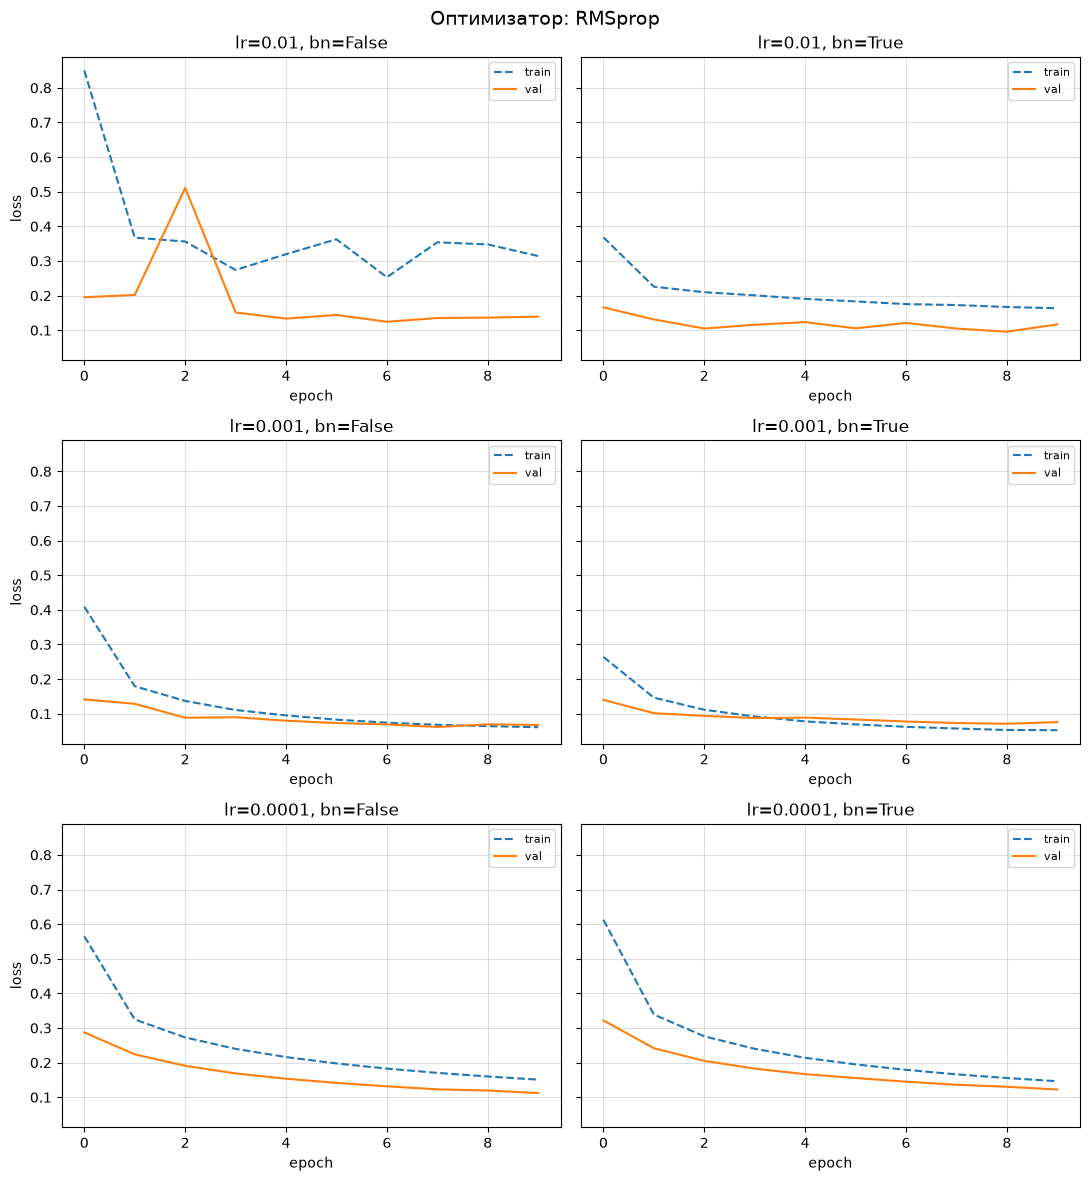

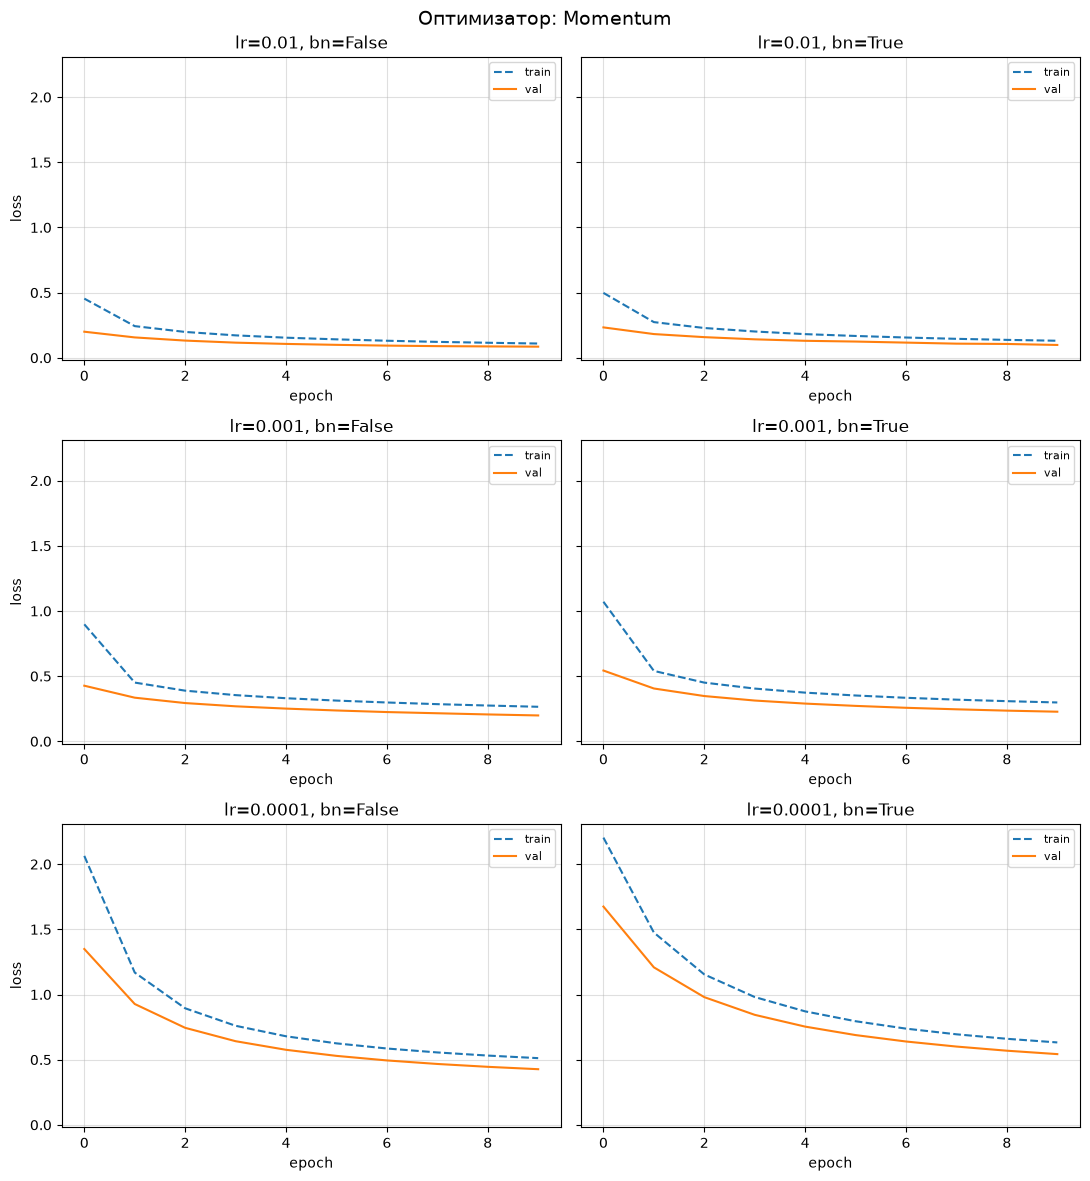

In [14]:
def plot_sweep(opt_name):
    fig, axes = plt.subplots(3, 2, figsize=(11, 12), sharey=True)
    for row, lr in enumerate(LEARNING_RATES):
        for col, use_bn in enumerate([False, True]):
            tag = f"{opt_name}, lr={lr}, bn={use_bn}"
            ax = axes[row, col]
            hist = results[tag]["history"]
            ax.plot(hist["train_loss"], linestyle="--", label="train", linewidth=1.5)
            ax.plot(hist["val_loss"], label="val", linewidth=1.5)
            ax.set_title(f"lr={lr}, bn={use_bn}")
            ax.set_xlabel("epoch")
            ax.grid(True, alpha=0.4)
            if col == 0:
                ax.set_ylabel("loss")
            ax.legend(fontsize=8)
    fig.suptitle(f"Оптимизатор: {opt_name}", fontsize=14)
    plt.tight_layout()
    plt.show()

for opt in OPTIMIZERS:
    plot_sweep(opt)

Сведём результаты в таблицу и отберём топ-5 конфигураций по точности на валидации.

In [15]:
rows = []
for tag, res in results.items():
    h = res["history"]
    rows.append({"config": tag, "train_loss": h["train_loss"][-1],
                 "val_loss": h["val_loss"][-1], "val_acc": h["val_acc"][-1],
                 "train_acc": h["train_acc"][-1], "grad_err": h["grad_err"][-1]})
df = pd.DataFrame(rows).sort_values("val_acc", ascending=False).reset_index(drop=True)
df.round(4)

top5_tags = df.head(5)["config"].tolist()
print("Топ-5 по val acc:")
print(df[["config", "val_acc"]].head(5).to_string(index=False))
df.round(4)

Топ-5 по val acc:
                     config  val_acc
RMSprop, lr=0.001, bn=False 0.980167
   Adam, lr=0.001, bn=False 0.979667
    Adam, lr=0.001, bn=True 0.979333
 RMSprop, lr=0.001, bn=True 0.978667
Momentum, lr=0.01, bn=False 0.975833


,config,train_loss,val_loss,val_acc,train_acc,grad_err
0,"RMSprop, lr=0.001, bn=False",0.0609,0.0675,0.9802,0.9925,0.0
1,"Adam, lr=0.001, bn=False",0.0564,0.0678,0.9797,0.9958,0.0
2,"Adam, lr=0.001, bn=True",0.0510,0.0712,0.9793,0.9956,0.0
3,"RMSprop, lr=0.001, bn=True",0.0525,0.0757,0.9787,0.9942,0.0
4,"Momentum, lr=0.01, bn=False",0.1096,0.0856,0.9758,0.9854,0.0
5,"Momentum, lr=0.01, bn=True",0.1309,0.0986,0.9737,0.9801,0.0
6,"RMSprop, lr=0.0001, bn=False",0.1508,0.1121,0.9693,0.9729,0.0
7,"Adam, lr=0.01, bn=True",0.1769,0.1105,0.9665,0.9756,0.0
8,"RMSprop, lr=0.0001, bn=True",0.1462,0.1223,0.9665,0.9719,0.0
9,"Adam, lr=0.01, bn=False",0.1845,0.1235,0.9645,0.9697,0.0


## Оценка на тестовой выборке

Проверим топ-5 конфигураций (отобранных по валидации) на тесте.

                     config  test_loss  test_acc
RMSprop, lr=0.001, bn=False     0.0720    0.9796
   Adam, lr=0.001, bn=False     0.0713    0.9796
    Adam, lr=0.001, bn=True     0.0748    0.9784
 RMSprop, lr=0.001, bn=True     0.0817    0.9744
Momentum, lr=0.01, bn=False     0.0879    0.9740


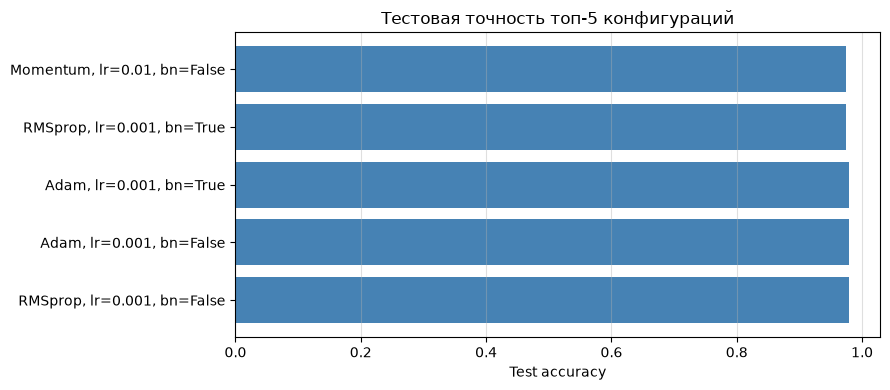

In [16]:
test_rows = []
for tag in top5_tags:
    res = results[tag]
    test_loss, test_acc = evaluate(res["model"], res["loss_fn"], X_test, y_test)
    test_rows.append({"config": tag, "test_loss": test_loss, "test_acc": test_acc})
test_df = pd.DataFrame(test_rows).sort_values("test_acc", ascending=False).reset_index(drop=True)
print(test_df.round(4).to_string(index=False))

plt.figure(figsize=(9, 4))
plt.barh(range(len(test_df)), test_df["test_acc"], color="steelblue")
plt.yticks(range(len(test_df)), test_df["config"])
plt.xlabel("Test accuracy")
plt.title("Тестовая точность топ-5 конфигураций")
plt.grid(axis="x", alpha=0.4)
plt.tight_layout()
plt.show()

## Анализ графиков

По графикам train/val loss видно следующее (только детали, заметные глазу, без точных чисел):

- **lr = 1e-4** (верхний ряд): train и val loss снижаются медленно и на всём протяжении обучения остаются
  заметно выше остальных — сеть учится слишком медленно;
- **lr = 1e-2** (нижний ряд): train loss резко падает уже к 1–2 эпохе и дальше почти не меняется; val loss выходит
  на плато и не улучшается, при этом на некоторых панелях вокруг этого плато видны заметные колебания;
- **lr = 1e-3** (средний ряд): train и val loss стабильно снижаются на протяжении всех 10 эпох и к концу обучения
  оказываются ниже, чем во всех остальных панелях;
- в среднем ряду (lr = 1e-3) у **Momentum** val loss к концу обучения заметно выше, чем у Adam и RMSprop — видно
  при сравнении фигур трёх оптимизаторов;
- разные варианты с/без BatchNorm в пределах одной панели различаются слабо — глазами основное различие между
  конфигурациями вносит learning rate.

## Выводы

- **Реализация верна**: на каждой эпохе всех 18 прогонов разностная проверка градиентов давала максимальную
  относительную ошибку порядка $10^{-6}$ и меньше (обычно $10^{-7}$–$10^{-9}$) — аналитические градиенты backprop
  совпадают с численными. Единственное исключение — смещение полносвязного слоя перед BatchNorm: его градиент
  практически нулевой (это не ошибка, см. раздел про проверку градиентов).
- **Подбор гиперпараметров**: решающую роль играет learning rate (видно по графикам): lr = 1e-2 — быстрое падение
  и плато без улучшений, lr = 1e-4 — слишком медленное обучение, lr = 1e-3 — лучший баланс.
  Лучшая конфигурация, отобранная по валидации, — **RMSprop, lr = 1e-3** (val accuracy 0.9802), на тесте она
  достигает accuracy **0.9796**.
- **Batch Normalization** (+2) реализован с нуля (обучение по статистикам батча, инференс по скользящим средним).
  На этой задаче BN не улучшает итоговую точность: лучшие конфигурации — без BN, разница с аналогичными версиями
  с BN порядка нескольких десятых процента. Зато при большом lr = 1e-2 версии с BN обучаются заметно стабильнее.
- **Оптимизаторы** (+2 балла Momentum/RMSprop, +1 балл Adam) реализованы с нуля и корректно минимизируют loss.
  Adam и RMSprop показали практически одинаковый результат (test accuracy 0.9796 у обеих), Momentum заметно отстаёт
  (0.9740) — и на валидации, и на тесте.
- **L2-регуляризация** ($\lambda = 10^{-4}$) входит в функцию потерь и учитывается в градиентах (проверено
  разностной оценкой). При lr = 1e-3 признаков переобучения на графиках нет; при lr = 1e-2 val loss выходит на
  плато без роста.
- Вся сеть (forward, backprop, loss, L2, BatchNorm, три оптимизатора) написана на `numpy` без автоградации; полный
  цикл обучения и подбора 18 конфигураций занимает около 9 минут на CPU.